In [31]:
# Imports

from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt

In [32]:
# Import des données MNIST depuis OpenML


directory = "data"
#telecharger jeu de donnée MNIST
mnist = fetch_openml('mnist_784', version=1, data_home=directory, as_frame=False, parser='liac-arff')



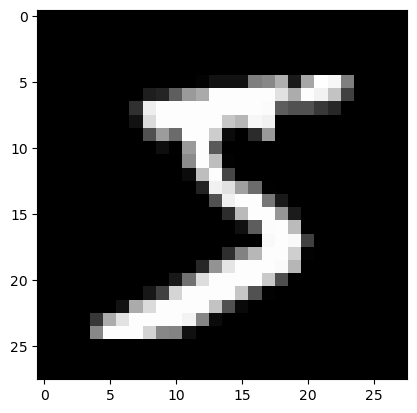

In [33]:
# Séparer les données en jeu d'entrainement et jeu de test 

Xtrain = mnist.data[0:60000]
Ytrain = mnist.target[0:60000]

Xtest = mnist.data[60000:70000]
Ytest = mnist.target[60000:70000]

#Afficher une image du jeu de train
plt.imshow(Xtrain[0].reshape(28,28), cmap='gray')

Ytrain = Ytrain.astype(int)
Ytest = Ytest.astype(int)

random_seed = 1234
Xtrain = mnist.data[0:60000] / 255.0
Xtest = mnist.data[60000:70000] / 255.0


# Algorithme ADABOOST

In [34]:
import numpy as np
from sklearn.base import clone

def adaboost(X, y, classifieur, nb_etape):

    y_signe = 2*y - 1 # On convertit les labels en {-1, +1}
    n = X.shape[0]
    w = np.ones(n) / n # Initialisation des poids

    classifieurs = []
    alphas = []

    for t in range(nb_etape):
        # On clone le classifieur pour avoir un nouveau modèle à chaque étape
        clf = clone(classifieur)
        clf.fit(X, y, sample_weight=w) # On entraine le classifieur avec les poids

        # On calcule l'erreur du classifieur
        pred = clf.predict(X)
        erreur = np.sum(w * (pred != y)) / np.sum(w)

        # On calcule le poids du classifieur
        alpha = 0.5 * np.log((1 - erreur) / (erreur + 1e-10)) # On ajoute un petit terme pour éviter la division par zéro

        # On met à jour les poids des exemples
        w *= np.exp(-alpha * y_signe * (2*pred - 1))
        w /= np.sum(w) # Normalisation des poids

        classifieurs.append(clf)
        alphas.append(alpha)

    return classifieurs, alphas

def adaboost_predict(X, classifieurs, alphas):
    score = np.zeros(X.shape[0])
    for clf, alpha in zip(classifieurs, alphas):
        score += alpha * (2 * clf.predict(X) - 1)
    return (score > 0).astype(int)


# Classifications binaires sur 1 paire de chiffre
## Paires de chiffres 3 et 8
### Stump


In [35]:
a, b = 3, 8

masque_train = (Ytrain == a) | (Ytrain == b)
masque_test = (Ytest == a) | (Ytest == b)

Xtrain_ab = Xtrain[masque_train]
Xtest_ab = Xtest[masque_test]

y_train_ab = (Ytrain[masque_train] == b).astype(int)
y_test_ab = (Ytest[masque_test] == b).astype(int)

print(Xtrain_ab.shape, Xtest_ab.shape)
print(y_train_ab[:10])
print(y_test_ab[:10])


(11982, 784) (1984, 784)
[0 0 0 1 0 0 1 1 0 1]
[0 0 0 0 0 1 0 0 0 1]


In [36]:
from sklearn.tree import DecisionTreeClassifier

stump = DecisionTreeClassifier(max_depth=1, random_state=random_seed)

classifieurs, alphas = adaboost(Xtrain_ab, y_train_ab, stump, nb_etape=50)

y_pred = adaboost_predict(Xtest_ab, classifieurs, alphas)
print("Taux de bonne classification :", (y_pred == y_test_ab).mean())


Taux de bonne classification : 0.9495967741935484


Matrice de confusion :
[[962  48]
 [ 52 922]]


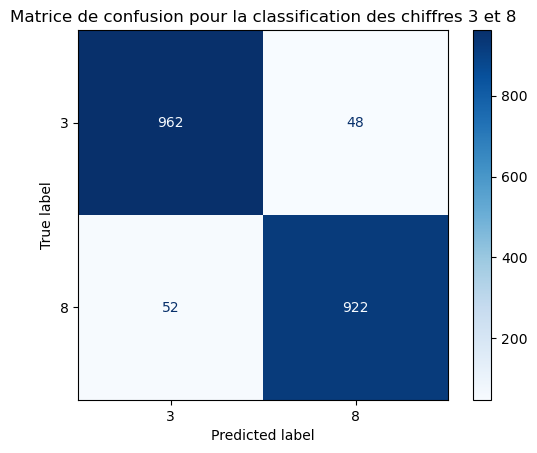

In [37]:
# matrice de confusion
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_ab, y_pred)
print("Matrice de confusion :")
print(cm)

ConfusionMatrixDisplay(cm, display_labels=[a, b]).plot(cmap = 'Blues')
plt.title("Matrice de confusion pour la classification des chiffres {} et {}".format(a, b)) 
plt.show()

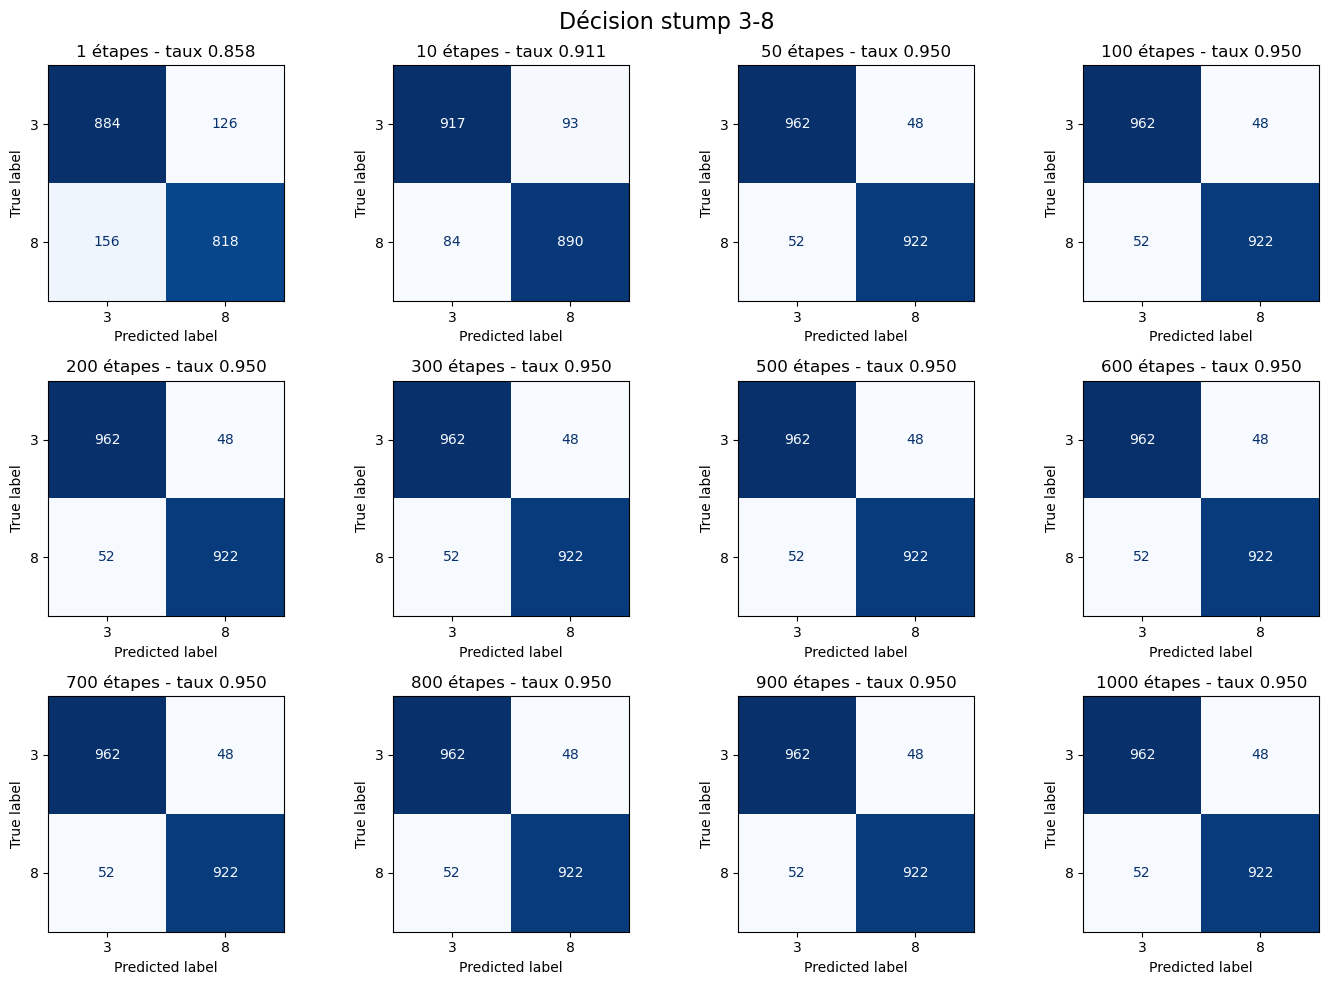

In [38]:
import os

liste_etapes = [1, 10, 50, 100, 200, 300, 500, 600, 700, 800, 900, 1000]

fig, axs = plt.subplots(3, 4, figsize=(14, 10))

for ax, n in zip(axs.flat, liste_etapes):
    y_pred = adaboost_predict(Xtest_ab, classifieurs[:n], alphas[:n])
    cm = confusion_matrix(y_test_ab, y_pred)
    taux = (y_pred == y_test_ab).mean()

    ConfusionMatrixDisplay(cm, display_labels=[a, b]).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{n} étapes - taux {taux:.3f}")

fig.suptitle(f"Décision stump {a}-{b}", fontsize=16)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig(f"figures/confusion_stump_{a}_{b}.png", dpi=150)

plt.show()


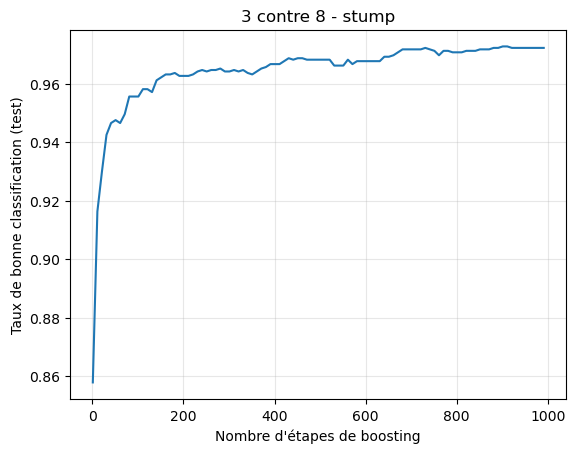

In [30]:
etapes = range(1, len(classifieurs) + 1, 10)
taux = [(adaboost_predict(Xtest_ab, classifieurs[:n], alphas[:n]) == y_test_ab).mean() for n in etapes]

plt.plot(etapes, taux)
plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("Taux de bonne classification (test)")
plt.title(f"{a} contre {b} - stump")
plt.grid(alpha=0.3)
plt.show()


## Perceptron

In [40]:
from sklearn.linear_model import Perceptron

perceptron = Perceptron(max_iter=5, tol=None, random_state=random_seed)

classifieurs_p, alphas_p = adaboost(Xtrain_ab, y_train_ab, perceptron, nb_etape=1000)


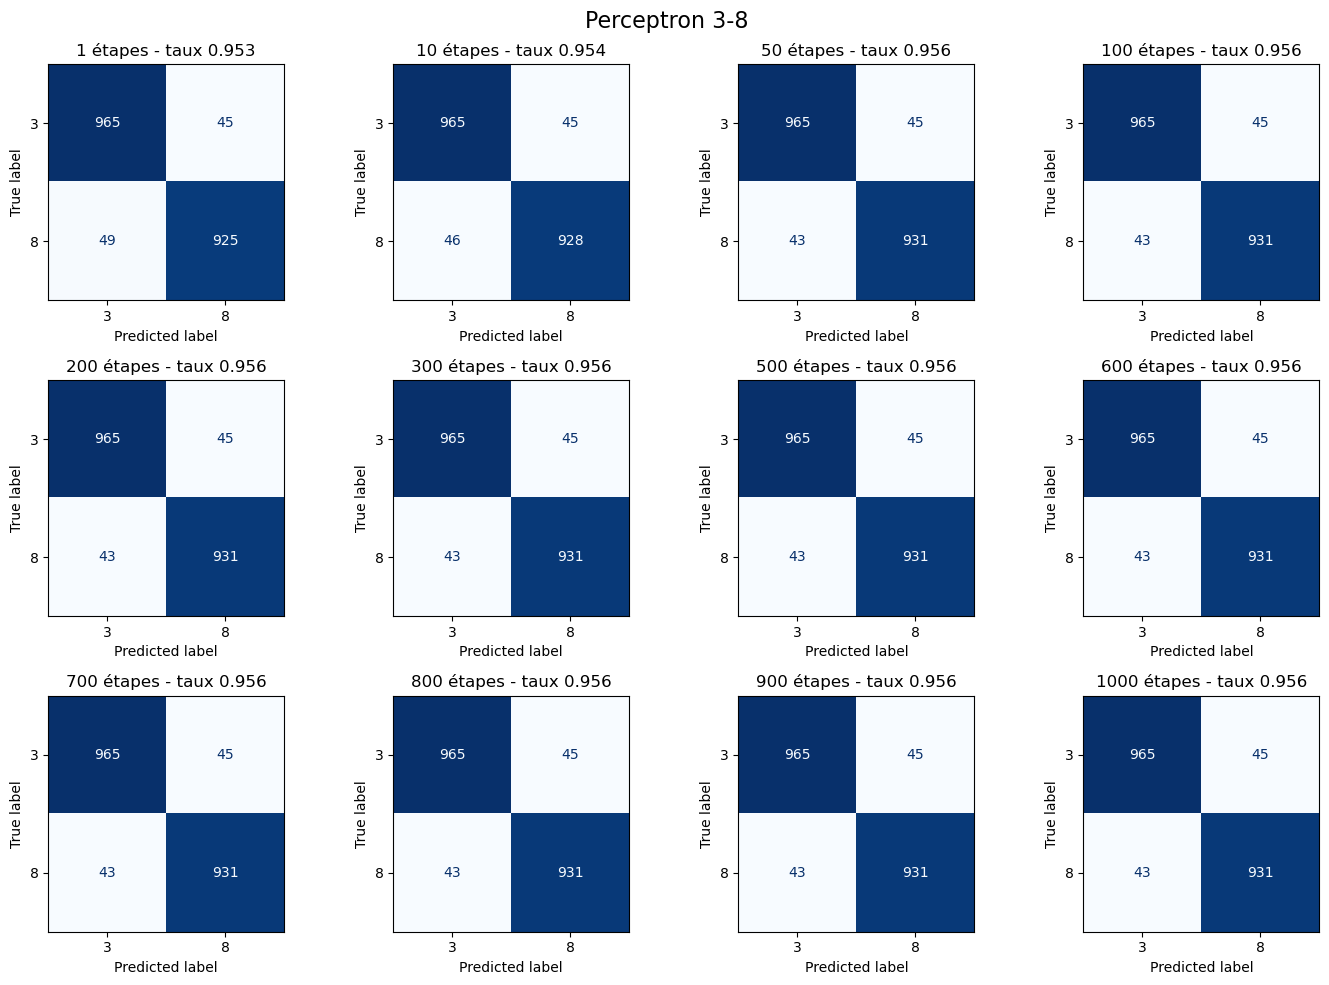

In [41]:
liste_etapes = [1, 10, 50, 100, 200, 300, 500, 600, 700, 800, 900, 1000]

fig, axs = plt.subplots(3, 4, figsize=(14, 10))

for ax, n in zip(axs.flat, liste_etapes):
    y_pred = adaboost_predict(Xtest_ab, classifieurs_p[:n], alphas_p[:n])
    cm = confusion_matrix(y_test_ab, y_pred)
    taux = (y_pred == y_test_ab).mean()

    ConfusionMatrixDisplay(cm, display_labels=[a, b]).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{n} étapes - taux {taux:.3f}")

fig.suptitle(f"Perceptron {a}-{b}", fontsize=16)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig(f"figures/confusion_perceptron_{a}_{b}.png", dpi=150)

plt.show()


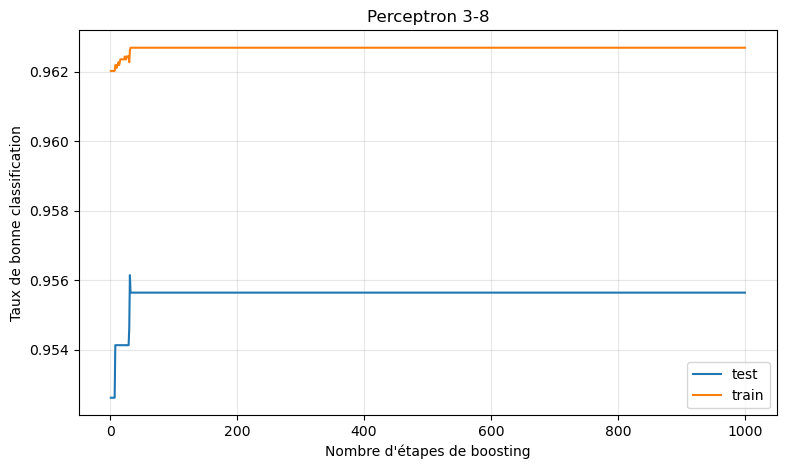

In [42]:
def courbe_taux(X, y, classifieurs, alphas):
    score = np.zeros(X.shape[0])
    taux = []
    for clf, alpha in zip(classifieurs, alphas):
        score += alpha * (2 * clf.predict(X) - 1)
        taux.append(((score > 0).astype(int) == y).mean())
    return taux

taux_test = courbe_taux(Xtest_ab, y_test_ab, classifieurs_p, alphas_p)
taux_train = courbe_taux(Xtrain_ab, y_train_ab, classifieurs_p, alphas_p)

fig = plt.figure(figsize=(9, 5))
plt.plot(range(1, len(taux_test) + 1), taux_test, label="test")
plt.plot(range(1, len(taux_train) + 1), taux_train, label="train")
plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("Taux de bonne classification")
plt.title(f"Perceptron {a}-{b}")
plt.legend()
plt.grid(alpha=0.3)

fig.savefig(f"figures/courbe_perceptron_{a}_{b}.png", dpi=150)
plt.show()


In [44]:
import optuna
from sklearn.model_selection import train_test_split

# Jeu de validation : 20 % du train, pour ne pas choisir les hyperparamètres sur le test
X_app, X_val, y_app, y_val = train_test_split(
    Xtrain_ab, y_train_ab, test_size=0.2, random_state=random_seed, stratify=y_train_ab
)

def objectif(trial):
    max_iter = trial.suggest_int("max_iter", 1, 30)
    eta0 = trial.suggest_float("eta0", 0.01, 10, log=True)
    penalty = trial.suggest_categorical("penalty", [None, "l2", "l1"])
    alpha_reg = trial.suggest_float("alpha", 1e-6, 1e-2, log=True)

    perceptron = Perceptron(max_iter=max_iter, tol=None, eta0=eta0,
                            penalty=penalty, alpha=alpha_reg, random_state=random_seed)

    clfs, als = adaboost(X_app, y_app, perceptron, nb_etape=100)
    y_pred = adaboost_predict(X_val, clfs, als)
    return (y_pred == y_val).mean()

# 50 essais Optuna
etude = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=random_seed))
etude.optimize(objectif, n_trials=50)

print("Meilleur taux (validation) :", etude.best_value)
print("Meilleurs hyperparamètres :", etude.best_params)

# Réentraînement sur tout le train avec les meilleurs hyperparamètres, puis évaluation sur le test
p = etude.best_params
perceptron_opt = Perceptron(max_iter=p["max_iter"], tol=None, eta0=p["eta0"],
                            penalty=p["penalty"], alpha=p["alpha"], random_state=random_seed)

classifieurs_po, alphas_po = adaboost(Xtrain_ab, y_train_ab, perceptron_opt, nb_etape=1000)

y_pred = adaboost_predict(Xtest_ab, classifieurs_po, alphas_po)
print("Taux de bonne classification (test) :", (y_pred == y_test_ab).mean())


[I 2026-11-16 09:07:33,879] A new study created in memory with name: no-name-db89d9e0-a39c-4489-a4fb-e726e32fdc94
[I 2026-11-16 09:07:42,643] Trial 0 finished with value: 0.9545264914476429 and parameters: {'max_iter': 6, 'eta0': 0.7350659626187652, 'penalty': 'l2', 'alpha': 1.23131854687439e-05}. Best is trial 0 with value: 0.9545264914476429.
[I 2026-11-16 09:07:54,312] Trial 1 finished with value: 0.9578639966624948 and parameters: {'max_iter': 9, 'eta0': 2.544582479781604, 'penalty': None, 'alpha': 0.00010092075760919585}. Best is trial 1 with value: 0.9578639966624948.
[I 2026-11-16 09:08:21,063] Trial 2 finished with value: 0.9516061743846475 and parameters: {'max_iter': 21, 'eta0': 1.3743776400634122, 'penalty': 'l2', 'alpha': 1.13520370105419e-06}. Best is trial 1 with value: 0.9578639966624948.
[I 2026-11-16 09:08:59,750] Trial 3 finished with value: 0.9578639966624948 and parameters: {'max_iter': 24, 'eta0': 4.445530271720049, 'penalty': 'l2', 'alpha': 2.9874182104867236e-05}

Meilleur taux (validation) : 0.9603671255736337
Meilleurs hyperparamètres : {'max_iter': 4, 'eta0': 0.08624408156368243, 'penalty': 'l2', 'alpha': 0.0004214211673359852}
Taux de bonne classification (test) : 0.9647177419354839


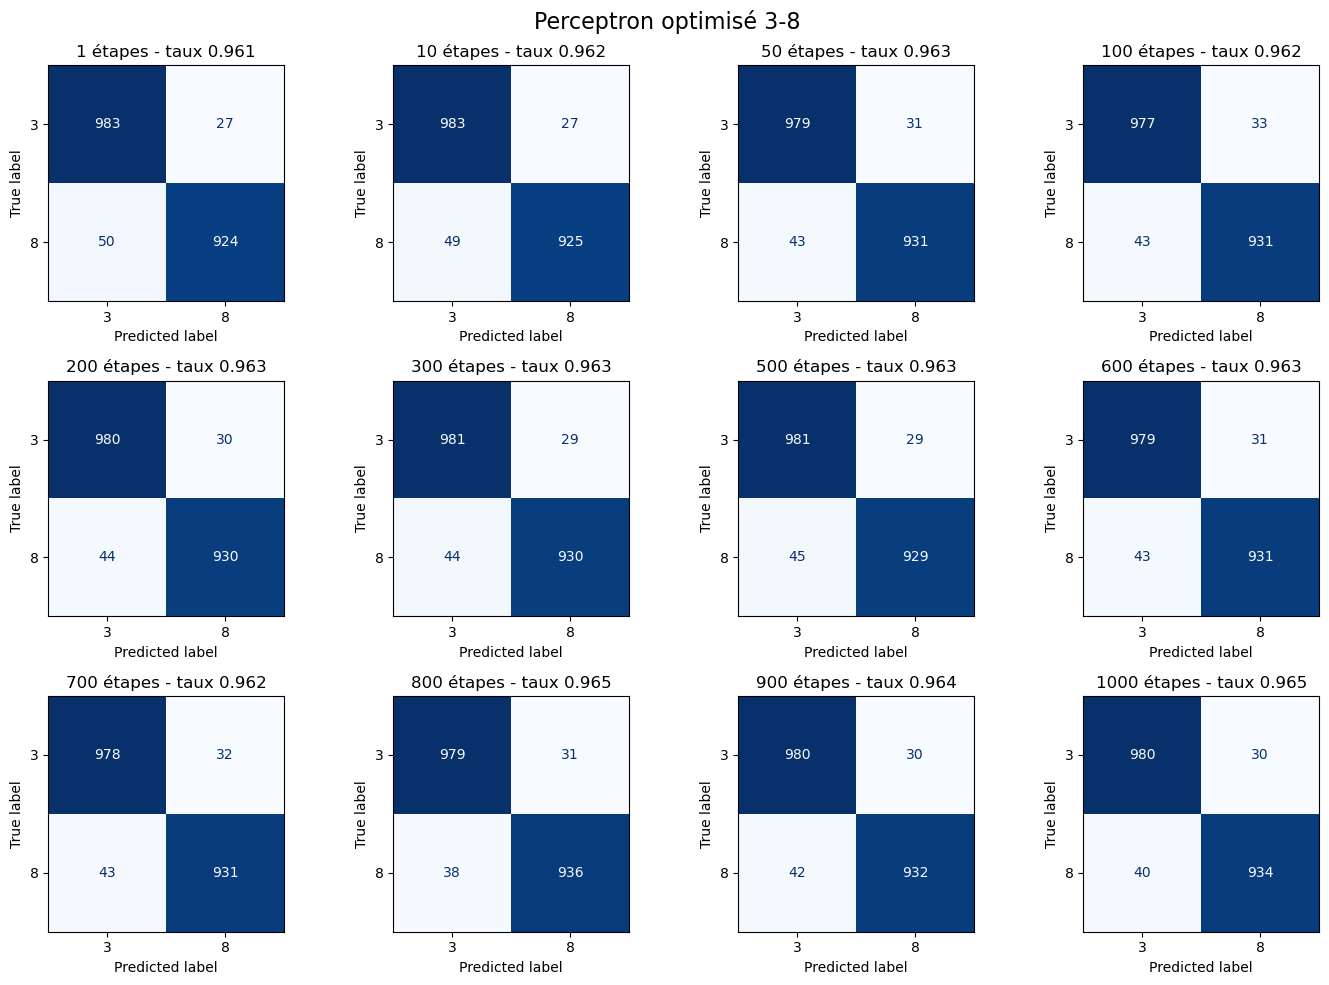

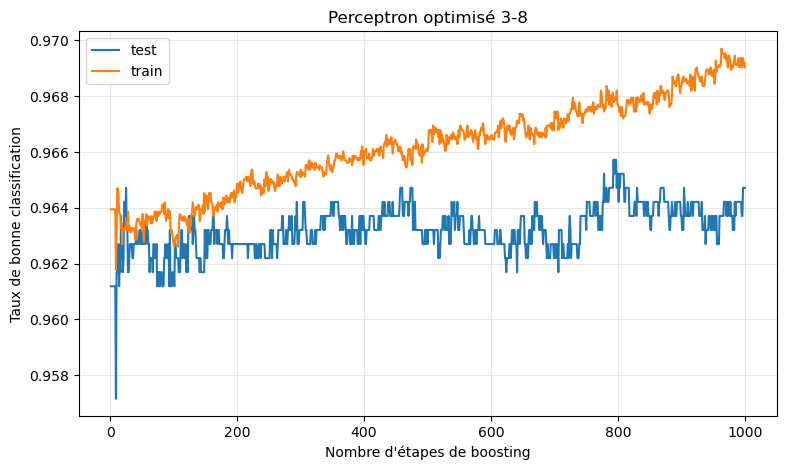

In [45]:
# Grille des matrices de confusion
liste_etapes = [1, 10, 50, 100, 200, 300, 500, 600, 700, 800, 900, 1000]

fig, axs = plt.subplots(3, 4, figsize=(14, 10))

for ax, n in zip(axs.flat, liste_etapes):
    y_pred = adaboost_predict(Xtest_ab, classifieurs_po[:n], alphas_po[:n])
    cm = confusion_matrix(y_test_ab, y_pred)
    taux = (y_pred == y_test_ab).mean()

    ConfusionMatrixDisplay(cm, display_labels=[a, b]).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{n} étapes - taux {taux:.3f}")

fig.suptitle(f"Perceptron optimisé {a}-{b}", fontsize=16)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig(f"figures/confusion_perceptron_opt_{a}_{b}.png", dpi=150)
plt.show()

# Courbe du taux de bonne classification
taux_test = courbe_taux(Xtest_ab, y_test_ab, classifieurs_po, alphas_po)
taux_train = courbe_taux(Xtrain_ab, y_train_ab, classifieurs_po, alphas_po)

fig = plt.figure(figsize=(9, 5))
plt.plot(range(1, len(taux_test) + 1), taux_test, label="test")
plt.plot(range(1, len(taux_train) + 1), taux_train, label="train")
plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("Taux de bonne classification")
plt.title(f"Perceptron optimisé {a}-{b}")
plt.legend()
plt.grid(alpha=0.3)

fig.savefig(f"figures/courbe_perceptron_opt_{a}_{b}.png", dpi=150)
plt.show()


### Arbre de décision

In [46]:
profondeurs = [3, 5, 10]
NB_ETAPES_ARBRE = 200

resultats_arbres = {}
for prof in profondeurs:
    arbre = DecisionTreeClassifier(max_depth=prof, random_state=random_seed)
    resultats_arbres[prof] = adaboost(Xtrain_ab, y_train_ab, arbre, nb_etape=NB_ETAPES_ARBRE)
    print(f"Profondeur {prof} terminée")


Profondeur 3 terminée
Profondeur 5 terminée
Profondeur 10 terminée


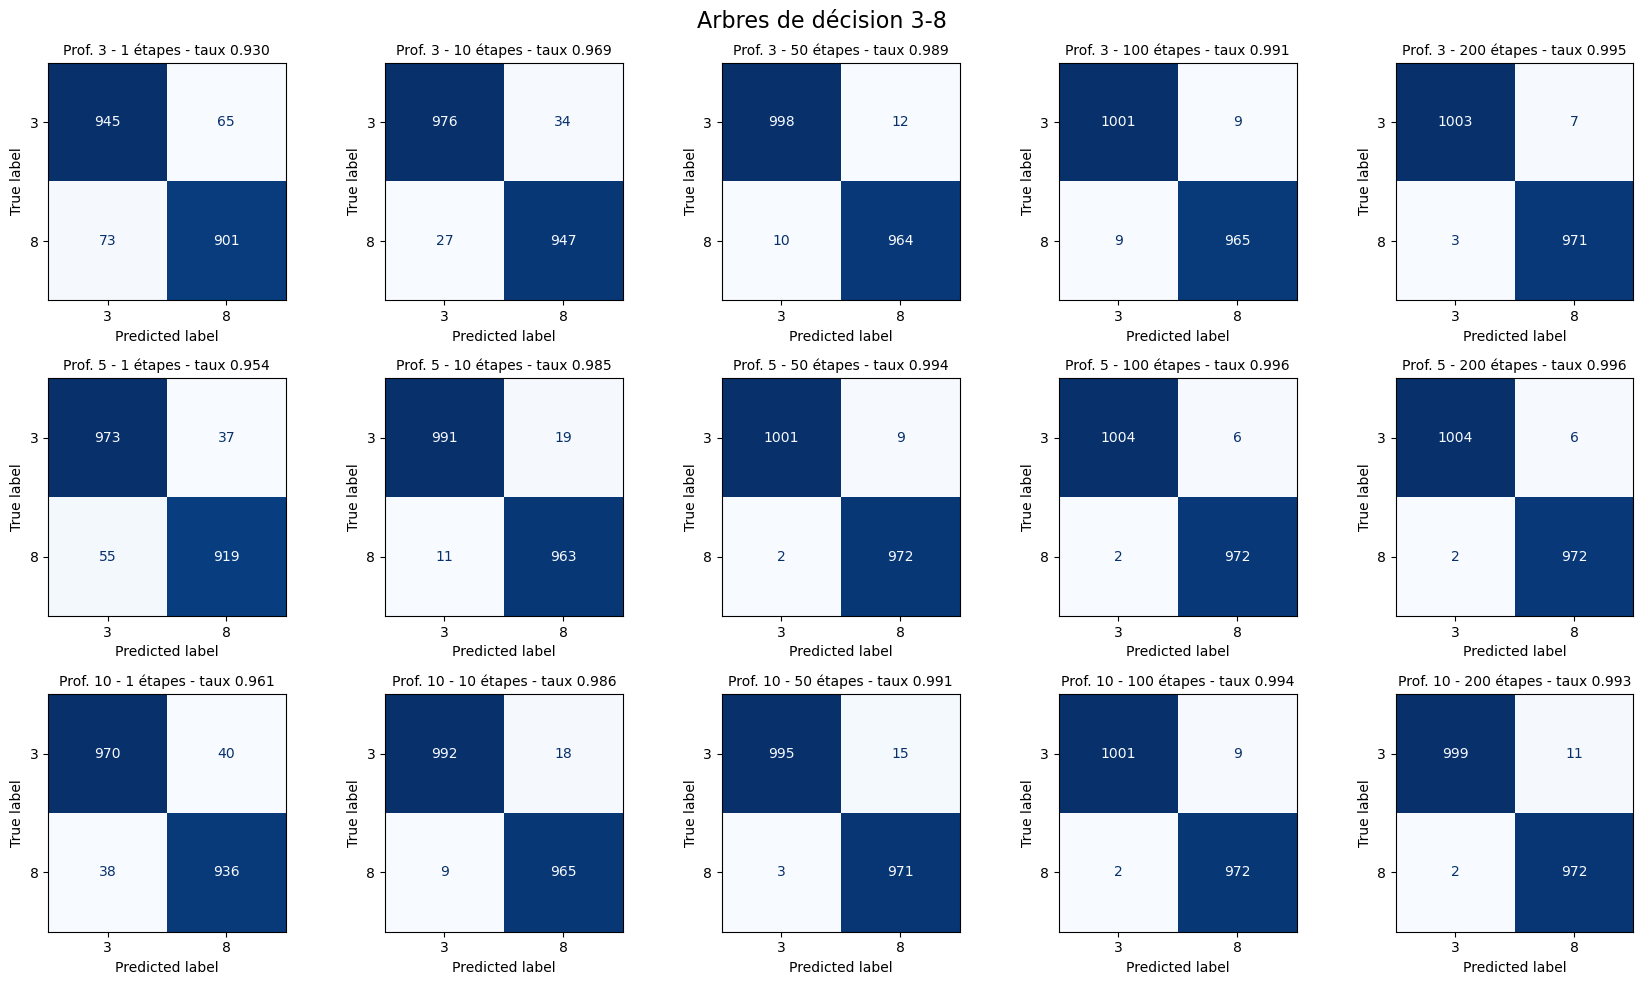

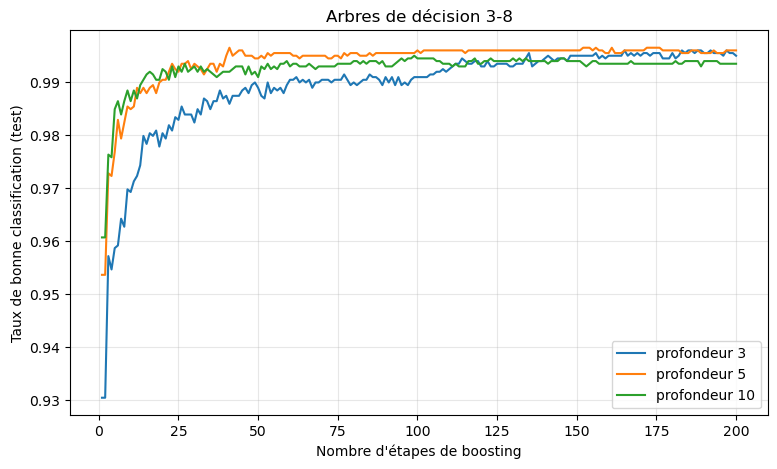

In [47]:
# Grille : une ligne par profondeur, une colonne par nombre d'étapes
liste_etapes = [1, 10, 50, 100, 200]

fig, axs = plt.subplots(len(profondeurs), len(liste_etapes), figsize=(17, 10))

for i, prof in enumerate(profondeurs):
    clfs, als = resultats_arbres[prof]
    for j, n in enumerate(liste_etapes):
        y_pred = adaboost_predict(Xtest_ab, clfs[:n], als[:n])
        cm = confusion_matrix(y_test_ab, y_pred)
        taux = (y_pred == y_test_ab).mean()

        ax = axs[i, j]
        ConfusionMatrixDisplay(cm, display_labels=[a, b]).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f"Prof. {prof} - {n} étapes - taux {taux:.3f}", fontsize=10)

fig.suptitle(f"Arbres de décision {a}-{b}", fontsize=16)
plt.tight_layout()

os.makedirs("figures", exist_ok=True)
fig.savefig(f"figures/confusion_arbres_{a}_{b}.png", dpi=150)
plt.show()

# Courbe : taux sur le test pour chaque profondeur
fig = plt.figure(figsize=(9, 5))
for prof in profondeurs:
    clfs, als = resultats_arbres[prof]
    taux_test = courbe_taux(Xtest_ab, y_test_ab, clfs, als)
    plt.plot(range(1, len(taux_test) + 1), taux_test, label=f"profondeur {prof}")

plt.xlabel("Nombre d'étapes de boosting")
plt.ylabel("Taux de bonne classification (test)")
plt.title(f"Arbres de décision {a}-{b}")
plt.legend()
plt.grid(alpha=0.3)

fig.savefig(f"figures/courbe_arbres_{a}_{b}.png", dpi=150)
plt.show()
